In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
X_train = np.array([[0.5, 1.5], [1,1], [1.5, 0.5], [3, 0.5], [2, 2], [1, 2.5]])  #(m,n)
y_train = np.array([0, 0, 0, 1, 1, 1])  # (m,)

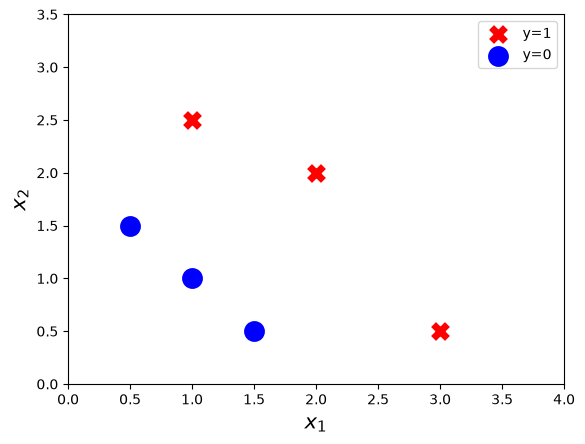

In [18]:
# now let's plot and visualize the data
positive = y_train == 1
negative = y_train == 0

plt.scatter(X_train[positive, 0], X_train[positive, 1], marker='x', c='r', lw=5, s=100, label='y=1')
plt.scatter(X_train[negative, 0], X_train[negative, 1], marker='o', c='b', lw=5, s=100, label='y=0')
plt.xlabel('$x_1$', fontsize=15)
plt.ylabel('$x_2$', fontsize=15)
plt.axis([0,4,0,3.5])
plt.legend()
plt.show()

## Cost function

In a previous lab, you developed the *logistic loss* function. Recall, loss is defined to apply to one example. Here you combine the losses to form the **cost**, which includes all the examples.


Recall that for logistic regression, the cost function is of the form 

$$ J(\mathbf{w},b) = \frac{1}{m} \sum_{i=0}^{m-1} \left[ loss(f_{\mathbf{w},b}(\mathbf{x}^{(i)}), y^{(i)}) \right] \tag{1}$$

where
* $loss(f_{\mathbf{w},b}(\mathbf{x}^{(i)}), y^{(i)})$ is the cost for a single data point, which is:

    $$loss(f_{\mathbf{w},b}(\mathbf{x}^{(i)}), y^{(i)}) = -y^{(i)} \log\left(f_{\mathbf{w},b}\left( \mathbf{x}^{(i)} \right) \right) - \left( 1 - y^{(i)}\right) \log \left( 1 - f_{\mathbf{w},b}\left( \mathbf{x}^{(i)} \right) \right) \tag{2}$$
    
*  where m is the number of training examples in the data set and:
$$
\begin{align}
  f_{\mathbf{w},b}(\mathbf{x^{(i)}}) &= g(z^{(i)})\tag{3} \\
  z^{(i)} &= \mathbf{w} \cdot \mathbf{x}^{(i)}+ b\tag{4} \\
  g(z^{(i)}) &= \frac{1}{1+e^{-z^{(i)}}}\tag{5} 
\end{align}
$$
 

In [19]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

In [20]:
def compute_cost_logistic(X, y, w, b):
    m = X.shape[0] # no. of training examples
    cost = 0.0
    for i in range(m):
        z = np.dot(X[i], w) + b
        f_wb_i = sigmoid(z)
        loss = -y[i] * np.log(f_wb_i) - (1 - y[i]) * np.log(1 - f_wb_i)
        cost += loss
    cost = cost / m
    return cost

In [21]:
# example of calculation
w_tmp = np.array([1., 1.])
b_tmp = -3
print(f"Cost: {compute_cost_logistic(X_train, y_train, w_tmp, b_tmp)}")

Cost: 0.36686678640551745


## Example
Now, let's see what the cost function output is for a different value of $w$. 

* In a previous lab, you plotted the decision boundary for  $b = -3, w_0 = 1, w_1 = 1$. That is, you had `b = -3, w = np.array([1,1])`.

* Let's say you want to see if $b = -4, w_0 = 1, w_1 = 1$, or `b = -4, w = np.array([1,1])` provides a better model.

Let's first plot the decision boundary for these two different $b$ values to see which one fits the data better.

* For $b = -3, w_0 = 1, w_1 = 1$, we'll plot $-3 + x_0+x_1 = 0$ (shown in blue)
* For $b = -4, w_0 = 1, w_1 = 1$, we'll plot $-4 + x_0+x_1 = 0$ (shown in magenta)

In [22]:
# now let's plot both boundaries
x0 = np.arange(0,6)
x1 = 3 - x0
x1_other = 4 - x0

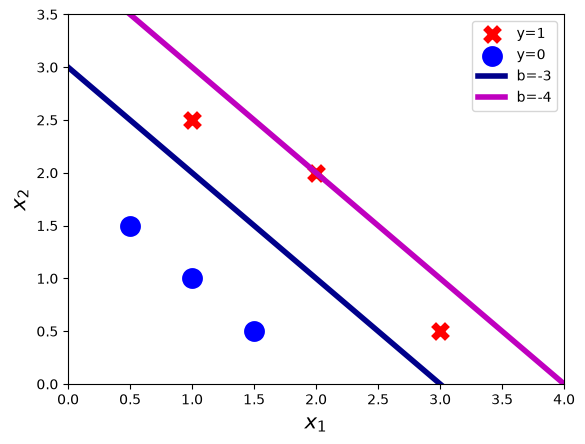

In [26]:
positive = y_train == 1
negative = y_train == 0

plt.scatter(X_train[positive, 0], X_train[positive, 1], marker='x', c='r', lw=5, s=100, label='y=1')
plt.scatter(X_train[negative, 0], X_train[negative, 1], marker='o', c='b', lw=5, s=100, label='y=0')

plt.plot(x0, x1, c='darkblue', label='b=-3', lw=4)
plt.plot(x0, x1_other, c='m', label='b=-4', lw=4)

plt.xlabel('$x_1$', fontsize=15)
plt.ylabel('$x_2$', fontsize=15)
plt.axis([0,4,0,3.5])
plt.legend()
plt.show()

In [27]:
# as we can see above with our model is worse with parameter b = -4
# we can also compute that with the help of our logistic cost function
w = np.array([1,1])
b1 = -3
b2 = -4

print(f"Cost at b=-3: {compute_cost_logistic(X_train, y_train, w, b1)}")
print(f"Cost at b=-4: {compute_cost_logistic(X_train, y_train, w, b2)}")

Cost at b=-3: 0.36686678640551745
Cost at b=-4: 0.5036808636748461


In [28]:
# so cost is higher in b = -4 than other means it is not a good model our goal is to minimize the cost
# and find parameters where cost is minimum